# CSC 7210 – Intrusion Detection with Decision-Tree Learning
# Sadat Bin Faruque

## How to build / run

1. Log in to the NAIRR Cloudbank hub (`tntech.cloudbank.2i2c.cloud`) with @tntech.edu account.
2. Upload this notebook and the data file so the folder looks like this:
   ```
   IDS.ipynb
   UNSW-NB15/train_test_network.csv
   ```
   (If the data is somewhere else, change `RAW_DATA` in the **Configuration** cell.)
3. Run **Kernel → Restart Kernel and Run All Cells**. The default Python 3 kernel on Cloudbank
   already has NumPy and pandas, so nothing has to be installed.
4. Run time is about one to two minutes. All outputs are also written to the `output/` folder:
   - `attributes.txt`: attribute description file (program input 1)
   - `train.csv`, `test.csv`: training and test sets (program inputs 2 and 3)
   - `tree_type.txt`: the learned tree, printed pre-order with indentation
   - `results.txt`: accuracies, confusion matrix and the other experiment results

## 1. Configuration

In [1]:
import os, sys, time, math, platform
NOTEBOOK_START = time.time()
import numpy as np
import pandas as pd

RAW_DATA   = "UNSW-NB15/train_test_network.csv"   # data file provided on the LMS
OUT_DIR    = "output"
CLASS_ATTR = "type"     # the last column (the attack type / 'normal') is the class to predict
TEST_FRAC  = 0.30       # 70% training, 30% test
SEED       = 42         # fixed seed so the split can be reproduced
N_BINS     = 10         # number of equal-frequency bins for continuous attributes
MAX_VALUES = 25         # max distinct values kept for a discrete attribute (rest -> "__other__")

os.makedirs(OUT_DIR, exist_ok=True)
ATTR_FILE  = os.path.join(OUT_DIR, "attributes.txt")
TRAIN_FILE = os.path.join(OUT_DIR, "train.csv")
TEST_FILE  = os.path.join(OUT_DIR, "test.csv")

print("Python", platform.python_version(), "| NumPy", np.__version__, "| pandas", pd.__version__)
print("Machine:", platform.platform(), "|", os.cpu_count(), "CPUs")

def read_first(paths):
    # Container limits live in cgroup files on Linux (e.g. the Cloudbank hub); "n/a" elsewhere.
    for path in paths:
        try:
            return open(path).read().strip()
        except OSError:
            pass
    return "n/a"

mem_limit = read_first(["/sys/fs/cgroup/memory.max", "/sys/fs/cgroup/memory/memory.limit_in_bytes"])
cpu_limit = read_first(["/sys/fs/cgroup/cpu.max"])
if mem_limit.isdigit():
    mem_limit = f"{int(mem_limit) / 2**30:.2f} GB"
if len(cpu_limit.split()) == 2 and cpu_limit.split()[0].isdigit():
    quota, period = map(int, cpu_limit.split())
    cpu_limit = f"{quota / period:g} CPU(s)"
usable = len(os.sched_getaffinity(0)) if hasattr(os, "sched_getaffinity") else os.cpu_count()
print(f"Container limits: memory {mem_limit}, CPU {cpu_limit} | CPUs visible to this process: {usable}")

Python 3.13.14 | NumPy 2.4.6 | pandas 3.0.3
Machine: Linux-6.12.68+-x86_64-with-glibc2.39 | 4 CPUs
Container limits: memory 4.00 GB, CPU 2 CPU(s) | CPUs visible to this process: 4


## 2. Data preparation

**Train/test split.** A stratified random split (70% / 30%, fixed seed) keeps the class
proportions the same in both files. `mitm` has only 1,043 records, so stratifying matters.

**Attribute description file.** The algorithm makes one branch per attribute value, so every
attribute needs a finite, known set of values. Each line of `attributes.txt` holds
`name <TAB> kind <TAB> values...`, where kind is one of:

| kind | meaning |
|---|---|
| `discrete` | symbolic attribute; the listed values are its possible values. Values outside the list map to `__other__`. |
| `continuous` | numeric attribute; the listed numbers are **cut points**. A value falls into bin *i* when `cut[i-1] < x <= cut[i]`, so each bin is one attribute value. |
| `ignore` | not used for learning |
| `class` | the goal attribute; the listed values are the classes |

Decisions made when building the file (all computed **from the training set only**, so the
test set stays unseen):
- `src_ip` and `dst_ip` are ignored. They identify particular test-bed machines and would make
  the tree memorise hosts instead of learning attack behaviour.
- `label` (0/1) is ignored when the class is `type`, because it gives the answer away
  (`label = 0` exactly when `type = normal`).
- Ports are identifiers, not quantities, so they are treated as discrete. The `MAX_VALUES`
  most frequent values are kept and the rest become `__other__`. Other high-cardinality text
  fields (`dns_query`, `http_uri`, `http_user_agent`, ...) are handled the same way.
- Text columns and integer columns with few distinct values (≤ 50) are discrete. `-` (field
  not present in the connection) is kept as an ordinary value, because whether a field is
  present is useful information in itself.
- The remaining numeric columns (`duration`, byte and packet counts, ...) are continuous and
  are split into up to `N_BINS` equal-frequency bins.

In [2]:
def stratified_split(df, class_col, test_frac, seed):
    # Shuffle each class separately and send test_frac of it to the test set.
    rng = np.random.default_rng(seed)
    test_idx = []
    for _, grp in df.groupby(class_col, sort=True):
        idx = grp.index.to_numpy().copy()
        rng.shuffle(idx)
        test_idx.extend(idx[:int(round(len(idx) * test_frac))])
    test_mask = df.index.isin(test_idx)
    return df[~test_mask], df[test_mask]


def build_attribute_file(train_df, class_col, path, ignore=(), force_discrete=(),
                         n_bins=N_BINS, max_values=MAX_VALUES):
    # Write the attribute description file using only the training data.
    lines = []
    for col in train_df.columns:
        s = train_df[col]
        if col == class_col:
            vals = sorted(s.astype(str).unique())
            lines.append([col, "class"] + vals)
        elif col in ignore:
            lines.append([col, "ignore"])
        elif col in force_discrete or not pd.api.types.is_numeric_dtype(s) or \
                (pd.api.types.is_integer_dtype(s) and s.nunique() <= 50):
            counts = s.astype(str).value_counts()
            vals = list(counts.index[:max_values])
            if len(counts) > max_values:
                vals.append("__other__")
            lines.append([col, "discrete"] + vals)
        else:
            qs = np.unique(np.quantile(s.to_numpy(dtype=float), np.linspace(0, 1, n_bins + 1)[1:-1]))
            lines.append([col, "continuous"] + [repr(float(q)) for q in qs])
    with open(path, "w") as f:
        f.write("# name<TAB>kind<TAB>values   (kind: discrete | continuous(cut points) | ignore | class)\n")
        for parts in lines:
            f.write("\t".join(parts) + "\n")


raw = pd.read_csv(RAW_DATA, low_memory=False, encoding="utf-8-sig")
print("Raw data:", raw.shape[0], "records x", raw.shape[1], "columns")
print("Exact duplicate records:", raw.duplicated().sum(), "(kept, the data is used as provided)")
print("\nClass distribution:\n" + raw[CLASS_ATTR].value_counts().to_string())

train_df, test_df = stratified_split(raw, CLASS_ATTR, TEST_FRAC, SEED)
train_df.to_csv(TRAIN_FILE, index=False)
test_df.to_csv(TEST_FILE, index=False)
build_attribute_file(train_df, CLASS_ATTR, ATTR_FILE,
                     ignore={"src_ip", "dst_ip", "label"},
                     force_discrete={"src_port", "dst_port"})
print(f"\nWrote {TRAIN_FILE} ({len(train_df)} records), {TEST_FILE} ({len(test_df)} records), {ATTR_FILE}")

Raw data: 211043 records x 44 columns
Exact duplicate records: 20569 (kept, the data is used as provided)

Class distribution:
type
normal        50000
backdoor      20000
ddos          20000
dos           20000
injection     20000
password      20000
ransomware    20000
scanning      20000
xss           20000
mitm           1043

Wrote output/train.csv (147730 records), output/test.csv (63313 records), output/attributes.txt


In [3]:
# Show the attribute description file (long value lists shortened for display only).
with open(ATTR_FILE) as f:
    for line in f:
        parts = line.rstrip("\n").split("\t")
        shown = parts[:2] + parts[2:8] + (["... (%d values)" % (len(parts) - 2)] if len(parts) > 8 else [])
        print(" | ".join(p[:40] for p in shown))

# name<TAB>kind<TAB>values   (kind: disc
src_ip | ignore
src_port | discrete | 80 | 5353 | 1880 | 34296 | 4444 | 8080 | ... (26 values)
dst_ip | ignore
dst_port | discrete | 80 | 53 | 445 | 8080 | 443 | 21 | ... (26 values)
proto | discrete | tcp | udp | icmp
service | discrete | - | dns | http | ftp | ssl | gssapi | ... (9 values)
duration | continuous | 0.0 | 4e-06 | 4.8e-05 | 0.000171 | 0.001655 | 0.011385200000000012 | ... (8 values)
src_bytes | continuous | 0.0 | 52.0 | 147.0 | 244.0
dst_bytes | continuous | 0.0 | 298.0 | 1951.0
conn_state | discrete | S0 | SF | REJ | OTH | SH | S1 | ... (13 values)
missed_bytes | continuous | 0.0
src_pkts | continuous | 1.0 | 2.0 | 5.0 | 6.0
src_ip_bytes | continuous | 40.0 | 44.0 | 48.0 | 59.0 | 82.0 | 137.0 | ... (9 values)
dst_pkts | continuous | 0.0 | 1.0 | 3.0 | 6.0
dst_ip_bytes | continuous | 0.0 | 40.0 | 86.0 | 354.0 | 2239.0
dns_query | discrete | - | a2z3kk2ebqzso7.iot.ap-southeast-2.amazon | testphp.vulnweb.com | elasticsearch | elastic

## 3. The decision-tree learner

**Implementation notes**
- Every attribute value is encoded once as a small integer (its position in the attribute
  file), so the data becomes one integer matrix. Each tree node holds the row indices of its
  examples, and class counts come from `np.bincount`. That is all the NumPy the learner uses.
- Following the pseudocode, a node gets one branch for **every** value of the chosen
  attribute, including values with no training examples. Those branches are leaves that
  predict the parent's majority class (`default`).
- When printing, a node's branches with no training examples are merged into one line
  ("any of the other *k* values"), since they all predict the same class. Otherwise most of
  the printout would be empty branches.
- `learn_tree(..., stop_zero_gain=True)` adds one optional rule that is **not** in the
  pseudocode: stop when the best attribute has zero information gain. The required run uses
  the pure algorithm. Section 5.4 compares the two.
- Each internal node also stores its majority class. A test record whose value never appeared
  in the attribute file (only possible for a discrete attribute without `__other__`) gets
  that class.

In [4]:
OTHER = "__other__"

# ---------- Reading the input files ----------
def read_attribute_file(path):
    # Returns (attributes, class_name, class_values).
    # Each attribute is a dict: name, kind ('discrete'|'continuous'), values (labels), cuts.
    attributes, class_name, class_values = [], None, None
    with open(path) as f:
        for line in f:
            line = line.rstrip("\n")
            if not line or line.startswith("#"):
                continue
            parts = line.split("\t")
            name, kind, vals = parts[0], parts[1], parts[2:]
            if kind == "class":
                class_name, class_values = name, vals
            elif kind == "discrete":
                attributes.append({"name": name, "kind": kind, "values": vals})
            elif kind == "continuous":
                cuts = [float(v) for v in vals]
                labels = ([f"<= {cuts[0]:g}"] +
                          [f"({cuts[i-1]:g}, {cuts[i]:g}]" for i in range(1, len(cuts))] +
                          [f"> {cuts[-1]:g}"]) if cuts else ["any"]
                attributes.append({"name": name, "kind": kind, "values": labels, "cuts": cuts})
            elif kind != "ignore":
                raise ValueError(f"Unknown attribute kind '{kind}' for '{name}'")
    if class_name is None:
        raise ValueError("Attribute file has no 'class' line")
    return attributes, class_name, class_values


def encode_examples(path, attributes, class_name, class_values):
    # Read a data file and turn it into X (n x attributes, value indices) and y (class indices).
    # -1 in X marks a value not listed in the attribute file.
    df = pd.read_csv(path, low_memory=False, dtype=str, keep_default_na=False, encoding="utf-8-sig")
    X = np.empty((len(df), len(attributes)), dtype=np.int32)
    for j, a in enumerate(attributes):
        col = df[a["name"]]
        if a["kind"] == "continuous":
            X[:, j] = np.searchsorted(np.array(a["cuts"]), col.astype(float).to_numpy(), side="left")
        else:
            index = {v: i for i, v in enumerate(a["values"])}
            unknown = index.get(OTHER, -1)
            X[:, j] = col.map(lambda v: index.get(v, unknown)).to_numpy()
    cindex = {c: i for i, c in enumerate(class_values)}
    y = df[class_name].map(lambda c: cindex.get(c, -1)).to_numpy().astype(np.int32)
    return X, y


# ---------- The tree ----------
class Leaf:
    def __init__(self, label, n):
        self.label, self.n = label, n            # predicted class index, # training examples here

class Node:
    def __init__(self, attr, majority, n):
        self.attr, self.majority, self.n = attr, majority, n
        self.branches = []                       # branches[v] = subtree for value index v


def entropy(counts):
    total = counts.sum()
    if total == 0:
        return 0.0
    p = counts[counts > 0] / total
    return float(-(p * np.log2(p)).sum())


def information_gain(X, y, idx, a, n_values, n_classes):
    # Gain of splitting examples idx on attribute a.
    xs, ys = X[idx, a], y[idx]
    known = xs >= 0
    joint = np.bincount(xs[known] * n_classes + ys[known],
                        minlength=n_values * n_classes).reshape(n_values, n_classes)
    parent = entropy(np.bincount(ys, minlength=n_classes))
    sizes = joint.sum(axis=1)
    remainder = sum(sizes[v] / len(idx) * entropy(joint[v]) for v in range(n_values) if sizes[v])
    return parent - remainder


def choose_attribute(attrs, X, y, idx, n_values, n_classes):
    # Returns (best attribute, its gain).
    best, best_gain = None, -1.0
    for a in attrs:
        g = information_gain(X, y, idx, a, n_values[a], n_classes)
        if g > best_gain + 1e-12:
            best, best_gain = a, g
    return best, best_gain


def majority_value(y, idx, n_classes):
    return int(np.argmax(np.bincount(y[idx], minlength=n_classes)))


def decision_tree_learning(X, y, idx, attrs, default, n_values, n_classes, stop_zero_gain=False):
    if len(idx) == 0:
        return Leaf(default, 0)
    first = y[idx[0]]
    if np.all(y[idx] == first):
        return Leaf(int(first), len(idx))
    if not attrs:
        return Leaf(majority_value(y, idx, n_classes), len(idx))
    best, gain = choose_attribute(attrs, X, y, idx, n_values, n_classes)
    majority = majority_value(y, idx, n_classes)
    if stop_zero_gain and gain <= 1e-12:
        # Optional (not in the textbook): no attribute separates these examples, so stop here.
        return Leaf(majority, len(idx))
    tree = Node(best, majority, len(idx))
    rest = [a for a in attrs if a != best]
    col = X[idx, best]
    for v in range(n_values[best]):
        examples_v = idx[col == v]
        tree.branches.append(decision_tree_learning(X, y, examples_v, rest, majority,
                                                    n_values, n_classes, stop_zero_gain))
    return tree


def learn_tree(X, y, attributes, class_values, stop_zero_gain=False):
    sys.setrecursionlimit(max(10000, sys.getrecursionlimit()))
    n_values = [len(a["values"]) for a in attributes]
    idx = np.arange(len(y))
    default = majority_value(y, idx, len(class_values))
    return decision_tree_learning(X, y, idx, list(range(len(attributes))), default,
                                  n_values, len(class_values), stop_zero_gain)


# ---------- Using the tree ----------
def classify(tree, x):
    while isinstance(tree, Node):
        v = x[tree.attr]
        if v < 0:                      # value never seen in the attribute file
            return tree.majority
        tree = tree.branches[v]
    return tree.label


def predict(tree, X):
    return np.array([classify(tree, x) for x in X], dtype=np.int32)


def accuracy(tree, X, y):
    return float((predict(tree, X) == y).mean())


def tree_lines(tree, attributes, class_values, depth=0, label=None, show_empty=False):
    # Pre-order traversal: the node itself first, then each branch; 4 spaces of indent per level.
    # With show_empty=False, branches that received no training examples are merged into one line.
    pad = "    " * depth
    head = f"{pad}{label}: " if label is not None else pad
    if isinstance(tree, Leaf):
        note = f"{tree.n} examples" if tree.n else "no examples, parent majority"
        yield f"{head}--> {class_values[tree.label]}  ({note})"
        return
    a = attributes[tree.attr]
    yield f"{head}[test {a['name']}]  ({tree.n} examples, majority {class_values[tree.majority]})"
    empty = []
    for v, sub in enumerate(tree.branches):
        if isinstance(sub, Leaf) and sub.n == 0 and not show_empty:
            empty.append(a["values"][v])
            continue
        yield from tree_lines(sub, attributes, class_values, depth + 1,
                              f"{a['name']} = {a['values'][v]}", show_empty)
    if empty:
        # Branches without training examples all predict the parent's majority; print them as one line.
        yield (f"{pad}    {a['name']} = any of the other {len(empty)} values: "
               f"--> {class_values[tree.majority]}  (no examples, parent majority)")


def tree_stats(tree, depth=0):
    # (internal nodes, leaves, empty leaves, max depth)
    if isinstance(tree, Leaf):
        return 0, 1, int(tree.n == 0), depth
    stats = [tree_stats(b, depth + 1) for b in tree.branches]
    return (1 + sum(s[0] for s in stats), sum(s[1] for s in stats),
            sum(s[2] for s in stats), max(s[3] for s in stats))


# ---------- The program ----------
def print_slowly(lines, chunk=1000, pause=0.4):
    # Jupyter drops output sent faster than about 1 MB/s ("IOPub data rate exceeded"),
    # so a large tree is printed in chunks with short pauses.
    for i in range(0, len(lines), chunk):
        print("\n".join(lines[i:i + chunk]), flush=True)
        time.sleep(pause)


def main(attribute_file, training_file, test_file, tree_file=None, show_tree=True, output_file=None):
    t0 = time.time()
    attributes, class_name, class_values = read_attribute_file(attribute_file)
    X_train, y_train = encode_examples(training_file, attributes, class_name, class_values)
    X_test, y_test = encode_examples(test_file, attributes, class_name, class_values)
    t_load = time.time() - t0

    t0 = time.time()
    tree = learn_tree(X_train, y_train, attributes, class_values)
    t_learn = time.time() - t0

    lines = list(tree_lines(tree, attributes, class_values))
    if tree_file:
        with open(tree_file, "w") as f:
            f.write("\n".join(lines) + "\n")
    if show_tree:
        print("=" * 70 + "\nDECISION TREE (pre-order traversal)\n" + "=" * 70)
        print_slowly(lines)

    t0 = time.time()
    train_acc = accuracy(tree, X_train, y_train)
    test_acc = accuracy(tree, X_test, y_test)
    t_eval = time.time() - t0

    internal, leaves, empty, depth = tree_stats(tree)
    summary = ["=" * 70,
               f"Class attribute       : {class_name} ({len(class_values)} classes)",
               f"Attributes used       : {len(attributes)}",
               f"Training examples     : {len(y_train)}",
               f"Test examples         : {len(y_test)}",
               f"Tree size             : {internal} internal nodes, {leaves} leaves "
               f"({empty} without training examples), depth {depth}",
               f"Time (load/learn/eval): {t_load:.1f}s / {t_learn:.1f}s / {t_eval:.1f}s",
               f"Accuracy on TRAINING set: {train_acc:.4%}",
               f"Accuracy on TEST set    : {test_acc:.4%}",
               "=" * 70]
    print("\n".join(summary))
    if output_file:
        # Same text as printed above: the tree followed by the accuracies.
        with open(output_file, "w") as f:
            f.write("DECISION TREE (pre-order traversal)\n" + "\n".join(lines) + "\n" + "\n".join(summary) + "\n")
    return dict(tree=tree, attributes=attributes, class_values=class_values,
                X_train=X_train, y_train=y_train, X_test=X_test, y_test=y_test,
                train_acc=train_acc, test_acc=test_acc, t_learn=t_learn,
                size=(internal, leaves, empty, depth))

## 4. Run the program on the provided data set

Inputs: the attribute description file, the training set and the test set. The full tree
is printed below and also saved to `output/tree_type.txt`. The tree plus the accuracies go
to `output/program_output.txt`.

In [6]:
res = main(ATTR_FILE, TRAIN_FILE, TEST_FILE, tree_file=os.path.join(OUT_DIR, "tree_type.txt"),
           output_file=os.path.join(OUT_DIR, "program_output.txt"))

DECISION TREE (pre-order traversal)
[test dst_port]  (147730 examples, majority normal)
    dst_port = 80: [test src_ip_bytes]  (49578 examples, majority injection)
        src_ip_bytes = <= 40: [test conn_state]  (271 examples, majority xss)
            conn_state = SF: [test duration]  (3 examples, majority xss)
                duration = (4e-06, 4.8e-05]: --> ddos  (1 examples)
                duration = (0.0113852, 0.199771]: --> xss  (1 examples)
                duration = (0.199771, 1.32252]: --> xss  (1 examples)
                duration = any of the other 6 values: --> xss  (no examples, parent majority)
            conn_state = REJ: --> dos  (34 examples)
            conn_state = OTH: [test weird_name]  (24 examples, majority ddos)
                weird_name = -: [test dst_pkts]  (18 examples, majority ddos)
                    dst_pkts = <= 0: --> ddos  (3 examples)
                    dst_pkts = (0, 1]: [test src_port]  (13 examples, majority ddos)
                        sr

## 5. More evaluation

### 5.1 Confusion matrix and per-class accuracy (test set)
Rows are the true classes, columns the predicted ones. Recall is the fraction of each true
class classified correctly. Precision is the fraction of predictions of a class that are correct.

In [7]:
cv = res["class_values"]
pred_test = predict(res["tree"], res["X_test"])
y_test = res["y_test"]
K = len(cv)
cm = np.bincount(y_test * K + pred_test, minlength=K * K).reshape(K, K)
cm_df = pd.DataFrame(cm, index=[f"true {c}" for c in cv], columns=cv)
per_class = pd.DataFrame({
    "support":   cm.sum(axis=1),
    "recall":    np.diag(cm) / np.maximum(cm.sum(axis=1), 1),
    "precision": np.diag(cm) / np.maximum(cm.sum(axis=0), 1)}, index=cv).round(4)
print(cm_df.to_string()); print(); print(per_class.to_string())

                 backdoor  ddos   dos  injection  mitm  normal  password  ransomware  scanning   xss
true backdoor        5993     3     0          0     0       4         0           0         0     0
true ddos               0  5828     5         69     6      14         9           0         0    69
true dos                0     1  5613          7    63     250        10           0        56     0
true injection          0    52     1       5564     9       7       166           0        21   180
true mitm               0     1    12          8   265      15         4           1         3     4
true normal             0     7     9          4    24   14941         2           8         1     4
true password           0     4     6         49    55       0      5878           0         3     5
true ransomware         0     0     0          0     0      13         0        5987         0     0
true scanning           0     0    13          0    25       4         2           1      5

### 5.2 Attack vs. normal (binary view of the same tree)
An IDS mostly has to raise an alarm on attacks. Here any predicted attack type counts as
"attack", which gives the detection rate and the false-alarm rate.

In [8]:
normal = cv.index("normal")
true_att, pred_att = (y_test != normal), (pred_test != normal)
tp = int((true_att & pred_att).sum());  fn = int((true_att & ~pred_att).sum())
fp = int((~true_att & pred_att).sum()); tn = int((~true_att & ~pred_att).sum())
binary_acc = (tp + tn) / len(y_test)
print(f"Binary accuracy (attack vs normal): {binary_acc:.4%}")
print(f"Detection rate (attacks caught)   : {tp / (tp + fn):.4%}   missed attacks: {fn}")
print(f"False-alarm rate (normal flagged) : {fp / (fp + tn):.4%}   false alarms  : {fp}")

Binary accuracy (attack vs normal): 99.4188%
Detection rate (attacks caught)   : 99.3604%   missed attacks: 309
False-alarm rate (normal flagged) : 0.3933%   false alarms  : 59


### 5.2.1 Test records that also appear in the training set
The data contains exact duplicate records, so some test records are identical (in every
attribute) to a training record. Accuracy is reported separately for those and for the test
records the learner has truly never seen.

In [9]:
feat = [c for c in raw.columns if c not in ("label", "type")]
train_keys = set(map(tuple, train_df[feat].astype(str).values))
in_train = test_df[feat].astype(str).apply(tuple, axis=1).isin(train_keys).to_numpy()
correct = pred_test == y_test
dup_summary = (f"Test records identical to a training record: {in_train.sum()} of {len(y_test)} ({in_train.mean():.2%})\n"
               f"  accuracy on those records      : {correct[in_train].mean():.4%}\n"
               f"  accuracy on never-seen records : {correct[~in_train].mean():.4%}  ({(~in_train).sum()} records)")
print(dup_summary)

Test records identical to a training record: 7361 of 63313 (11.63%)
  accuracy on those records      : 99.8098%
  accuracy on never-seen records : 97.5497%  (55952 records)


### 5.3 Learning curve
The tree is retrained on growing random subsets of the training set and always tested on
the same full test set. This shows how much data the learner needs, and how far training
and test accuracy drift apart as the tree grows.

In [10]:
rng = np.random.default_rng(SEED)
X_tr, y_tr = res["X_train"], res["y_train"]
attributes = res["attributes"]
curve = []
for frac in [0.01, 0.05, 0.10, 0.25, 0.50, 1.00]:
    sub = rng.permutation(len(y_tr))[:int(frac * len(y_tr))]
    t0 = time.time()
    t = learn_tree(X_tr[sub], y_tr[sub], attributes, cv)
    secs = time.time() - t0
    internal, leaves, empty, depth = tree_stats(t)
    curve.append({"train fraction": frac, "train examples": len(sub),
                  "train acc": accuracy(t, X_tr[sub], y_tr[sub]),
                  "test acc": accuracy(t, res["X_test"], y_test),
                  "internal nodes": internal, "leaves": leaves, "depth": depth,
                  "learn time (s)": round(secs, 2)})
curve_df = pd.DataFrame(curve)
print(curve_df.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

 train fraction  train examples  train acc  test acc  internal nodes  leaves  depth  learn time (s)
         0.0100            1477     0.9919    0.9438             302    2036     40          0.3000
         0.0500            7386     0.9824    0.9660            1502    9570     40          1.2100
         0.1000           14773     0.9842    0.9710            2168   13762     40          1.7900
         0.2500           36932     0.9816    0.9748            4480   28284     40          3.7700
         0.5000           73865     0.9821    0.9769            5816   36785     40          5.0200
         1.0000          147730     0.9815    0.9781            9043   57045     40          8.0100


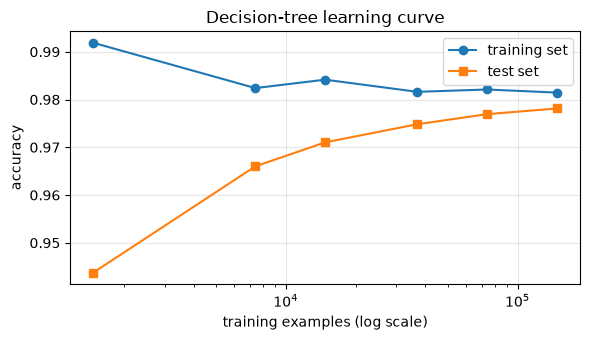

In [11]:
try:
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(6, 3.5))
    ax.plot(curve_df["train examples"], curve_df["train acc"], "o-", label="training set")
    ax.plot(curve_df["train examples"], curve_df["test acc"], "s-", label="test set")
    ax.set_xscale("log"); ax.set_xlabel("training examples (log scale)"); ax.set_ylabel("accuracy")
    ax.set_title("Decision-tree learning curve"); ax.grid(alpha=0.3); ax.legend()
    fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "learning_curve.png"), dpi=150); plt.show()
except ImportError:
    print("matplotlib not available, skipping plot")

### 5.4 Pure algorithm vs. stopping at zero information gain
Identical records with different classes cannot be separated by any attribute. The pure
algorithm still splits on them (with zero gain) until it runs out of attributes, which is
why the tree reaches the maximum depth. Here that is compared with stopping as soon as the
best gain is zero.

In [12]:
t0 = time.time()
tree_zg = learn_tree(X_tr, y_tr, attributes, cv, stop_zero_gain=True)
secs = time.time() - t0
cmp_df = pd.DataFrame([
    {"variant": "pure DTL (required run)", **dict(zip(["internal", "leaves", "empty leaves", "depth"], res["size"])),
     "train acc": res["train_acc"], "test acc": res["test_acc"], "learn time (s)": round(res["t_learn"], 2)},
    {"variant": "stop at zero gain", **dict(zip(["internal", "leaves", "empty leaves", "depth"], tree_stats(tree_zg))),
     "train acc": accuracy(tree_zg, X_tr, y_tr), "test acc": accuracy(tree_zg, res["X_test"], y_test),
     "learn time (s)": round(secs, 2)}])
print(cmp_df.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

                variant  internal  leaves  empty leaves  depth  train acc  test acc  learn time (s)
pure DTL (required run)      9043   57045         55591     40     0.9815    0.9781          7.9500
      stop at zero gain       692    4678          3227     12     0.9815    0.9781          2.1200


### 5.5 Binary experiment: predicting `label` (0 = normal, 1 = attack) directly
The same program is run with `label` as the class (and `type` ignored, since it would give
the answer away). Only a new attribute file is needed; the train/test files are reused.
The tree is saved to `output/tree_label.txt` instead of being printed here.

In [13]:
ATTR_FILE_BIN = os.path.join(OUT_DIR, "attributes_label.txt")
build_attribute_file(train_df.astype({"label": str}), "label", ATTR_FILE_BIN,
                     ignore={"src_ip", "dst_ip", "type"}, force_discrete={"src_port", "dst_port"})
res_bin = main(ATTR_FILE_BIN, TRAIN_FILE, TEST_FILE,
               tree_file=os.path.join(OUT_DIR, "tree_label.txt"), show_tree=False)

Class attribute       : label (2 classes)
Attributes used       : 40
Training examples     : 147730
Test examples         : 63313
Tree size             : 1594 internal nodes, 10107 leaves (9636 without training examples), depth 40
Time (load/learn/eval): 4.0s / 1.7s / 0.2s
Accuracy on TRAINING set: 99.5343%
Accuracy on TEST set    : 99.4330%


### 5.6 Most important attributes
Attributes tested near the root split the most examples. The table lists how often each
attribute is tested in the multi-class tree and how many training examples pass through
those tests.

In [14]:
from collections import defaultdict
use = defaultdict(lambda: [0, 0, 99])
def walk(t, d=0):
    if isinstance(t, Node):
        u = use[attributes[t.attr]["name"]]
        u[0] += 1; u[1] += t.n; u[2] = min(u[2], d)
        for b in t.branches: walk(b, d + 1)
walk(res["tree"])
imp = pd.DataFrame([(k, *v) for k, v in use.items()],
                   columns=["attribute", "times tested", "examples routed", "shallowest depth"])
imp = imp.sort_values("examples routed", ascending=False).reset_index(drop=True)
print(imp.head(15).to_string())

       attribute  times tested  examples routed  shallowest depth
0       dst_port             1           147730                 0
1   src_ip_bytes            82           103625                 1
2     conn_state           150            92941                 1
3       duration           112            58482                 2
4      dns_query           170            55077                 1
5       dst_pkts           188            45840                 2
6          proto           253            45502                 3
7       src_pkts           217            44943                 2
8      src_bytes           240            43789                 3
9      dst_bytes           206            42261                 2
10  dst_ip_bytes           233            41594                 2
11  missed_bytes           241            40182                 2
12       service           255            39233                 2
13      src_port           258            38036                 1
14     dns

### 5.7 Save a summary of all results

In [15]:
with open(os.path.join(OUT_DIR, "results.txt"), "w") as f:
    f.write("Multi-class (type)\n")
    f.write(f"  training accuracy: {res['train_acc']:.4%}\n  test accuracy: {res['test_acc']:.4%}\n")
    f.write(f"  tree (internal, leaves, empty leaves, depth): {res['size']}\n")
    f.write(f"  learn time: {res['t_learn']:.1f}s\n\n")
    f.write("Confusion matrix (test)\n" + cm_df.to_string() + "\n\n" + per_class.to_string() + "\n\n")
    f.write(f"Attack vs normal from multi-class tree: accuracy {binary_acc:.4%}, "
            f"detection {tp/(tp+fn):.4%}, false alarms {fp/(fp+tn):.4%}\n\n")
    f.write(dup_summary + "\n\n")
    f.write("Learning curve\n" + curve_df.to_string(index=False) + "\n\n")
    f.write("Pure DTL vs stop at zero gain\n" + cmp_df.to_string(index=False) + "\n\n")
    f.write("Binary (label)\n")
    f.write(f"  training accuracy: {res_bin['train_acc']:.4%}\n  test accuracy: {res_bin['test_acc']:.4%}\n")
    f.write(f"  tree (internal, leaves, empty leaves, depth): {res_bin['size']}\n\n")
    f.write("Attribute usage\n" + imp.head(15).to_string() + "\n")
print(open(os.path.join(OUT_DIR, "results.txt")).read())

import resource
peak = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss
peak_mb = peak / 2**20 if sys.platform == "darwin" else peak / 2**10   # bytes on macOS, KB on Linux
run_info = (f"Whole notebook run time: {time.time() - NOTEBOOK_START:.0f}s | peak memory of this kernel: {peak_mb:.0f} MB\n"
            f"Container limits: memory {mem_limit}, CPU {cpu_limit}")
with open(os.path.join(OUT_DIR, "results.txt"), "a") as f:
    f.write("\n" + run_info + "\n")
print(run_info)

Multi-class (type)
  training accuracy: 98.1453%
  test accuracy: 97.8125%
  tree (internal, leaves, empty leaves, depth): (9043, 57045, 55591, 40)
  learn time: 7.9s

Confusion matrix (test)
                 backdoor  ddos   dos  injection  mitm  normal  password  ransomware  scanning   xss
true backdoor        5993     3     0          0     0       4         0           0         0     0
true ddos               0  5828     5         69     6      14         9           0         0    69
true dos                0     1  5613          7    63     250        10           0        56     0
true injection          0    52     1       5564     9       7       166           0        21   180
true mitm               0     1    12          8   265      15         4           1         3     4
true normal             0     7     9          4    24   14941         2           8         1     4
true password           0     4     6         49    55       0      5878           0         3     5
